In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('../../Excercise_data/L07/penguins.csv')
data

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,species
0,-0.909073,0.819349,-1.444400,-0.573025,Adelie
1,-0.835598,0.163907,-1.082147,-0.509474,Adelie
2,-0.688650,0.466419,-0.430091,-1.208528,Adelie
3,-0.872335,1.777301,-0.792344,-0.700125,Adelie
4,-0.945810,0.365582,-1.444400,-0.731901,Adelie
...,...,...,...,...,...
320,0.578782,-1.701579,0.946471,0.920410,Gentoo
321,0.505308,-1.399067,1.018922,0.825084,Gentoo
322,1.166577,-0.693208,1.526076,1.968991,Gentoo
323,0.211411,-1.146975,0.801570,1.269937,Gentoo


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = data.drop(columns=['species'])
y = data.species
                   
X_train, X_test, y_train_raw, y_test_raw = train_test_split(X, y, train_size=0.8, random_state=12)

label_encoder = LabelEncoder().fit(y_train_raw)

y_train = pd.Series(data=label_encoder.transform(y_train_raw),name='species')
y_test = pd.Series(data=label_encoder.transform(y_test_raw), name='species')

#### Visualizing the relationship between features

Create a pairplot (`seaborn.pairplot`) to visualize the features. Use the `species` as a hue, to be able to distinguish different species.

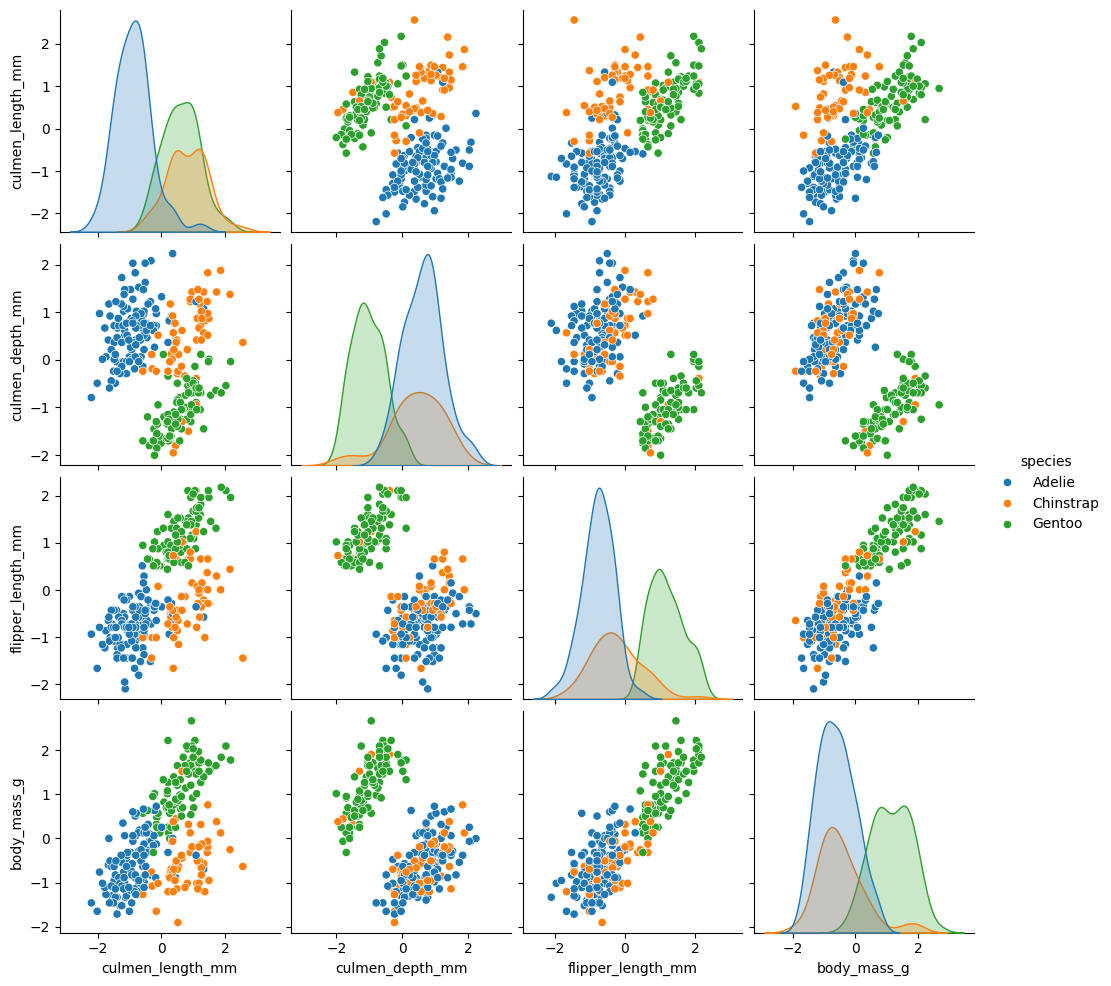

In [3]:
plot_data = X_train.copy(); plot_data['species']=y_train_raw.values;
sns.pairplot(data=plot_data, hue='species');


# Creating a PCA projection
Fit PCA on training features and store their scores in `X_proj_pca`. The full SVD here is deterministic; a seed does not select an attractive projection.

The supplied CSV already contains rescaled coordinates, not raw millimetres or grams. Its original scaling parameters are not supplied. Inspect the feature ranges and interpret these plots as geometric demonstrations.

In [4]:
from sklearn.decomposition import PCA

pca = PCA(svd_solver='full')
pca.fit(X_train)

PCA(svd_solver='full')

In [5]:
X_proj_pca = pca.transform(X_train)
X_proj_pca = pd.DataFrame(X_proj_pca, columns=[f'PC{i}' for i in range(1, 5)])
X_proj_pca

,PC1,PC2,PC3,PC4
0,-0.901394,0.085839,-0.338317,0.214005
1,-0.689737,0.483665,0.655917,0.209554
2,2.638389,0.030971,-0.173368,0.228922
3,-2.731550,-0.180849,0.160533,0.567401
4,-0.580401,0.245141,-0.450730,-0.348526
...,...,...,...,...
255,2.521258,-0.124581,0.245925,-0.426362
256,-2.000521,-2.076157,0.005553,-0.319857
257,2.209950,0.242032,-0.472449,-0.014738
258,2.668555,0.313754,-0.207394,-0.201763


# Comparing t-SNE and PCA projections
Compare original culmen length/depth, PC1/PC2, and the two t-SNE coordinates. Use `random_state=11` for reproducibility.

Use species colours only to interpret the unsupervised projection. Compare local visual separation without inferring classification performance. Predict what should remain similar before trying another seed.

In [6]:
from sklearn.manifold import TSNE

TSNE_embedded = TSNE(random_state=11).fit_transform(X_train)
TSNE_embedded.shape


(260, 2)

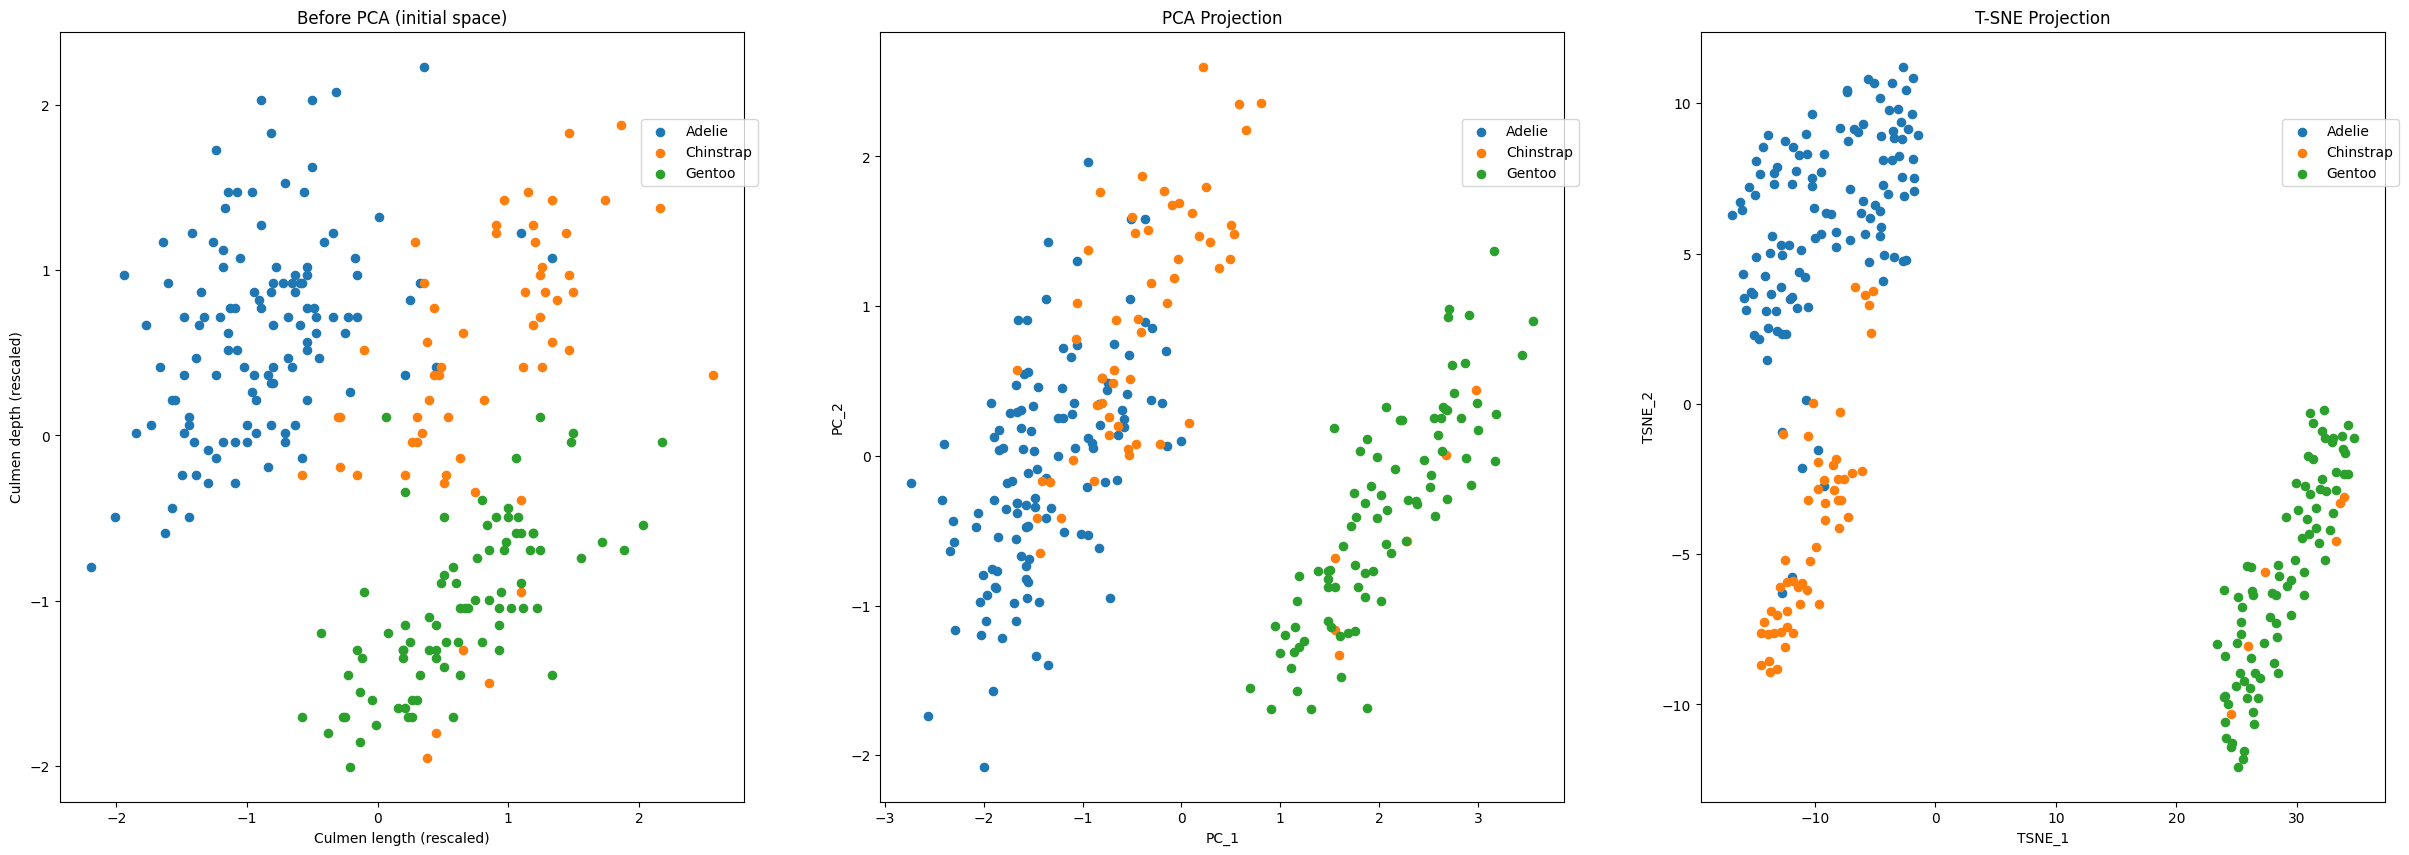

In [7]:
from utils import compare_embedding
X_proj_PC = X_proj_pca.values
compare_embedding({'Before PCA (initial space)':{'x':X_train.iloc[:,0].to_numpy(), 'y':X_train.iloc[:,1].to_numpy(),'xlabel':'Culmen length (rescaled)', 'ylabel':'Culmen depth (rescaled)'},
 'PCA Projection':{'x':X_proj_PC[:,0], 'y':X_proj_PC[:,1],'xlabel':'PC_1', 'ylabel':'PC_2'},
 'T-SNE Projection':{'x':TSNE_embedded[:,0], 'y':TSNE_embedded[:,1],'xlabel':'TSNE_1', 'ylabel':'TSNE_2'}},labels_data=y_train_raw.to_numpy(), marker_size=35)

# Comparing UMAP and PCA projections
Compare original culmen length/depth, PC1/PC2, and the two UMAP coordinates.

Which projection appears to separate species locally? Does visual separation establish out-of-sample classification accuracy?

In [8]:
from umap import UMAP 
umap_trans = UMAP(random_state=42, n_jobs=1)
X_umap = umap_trans.fit_transform(X_train)

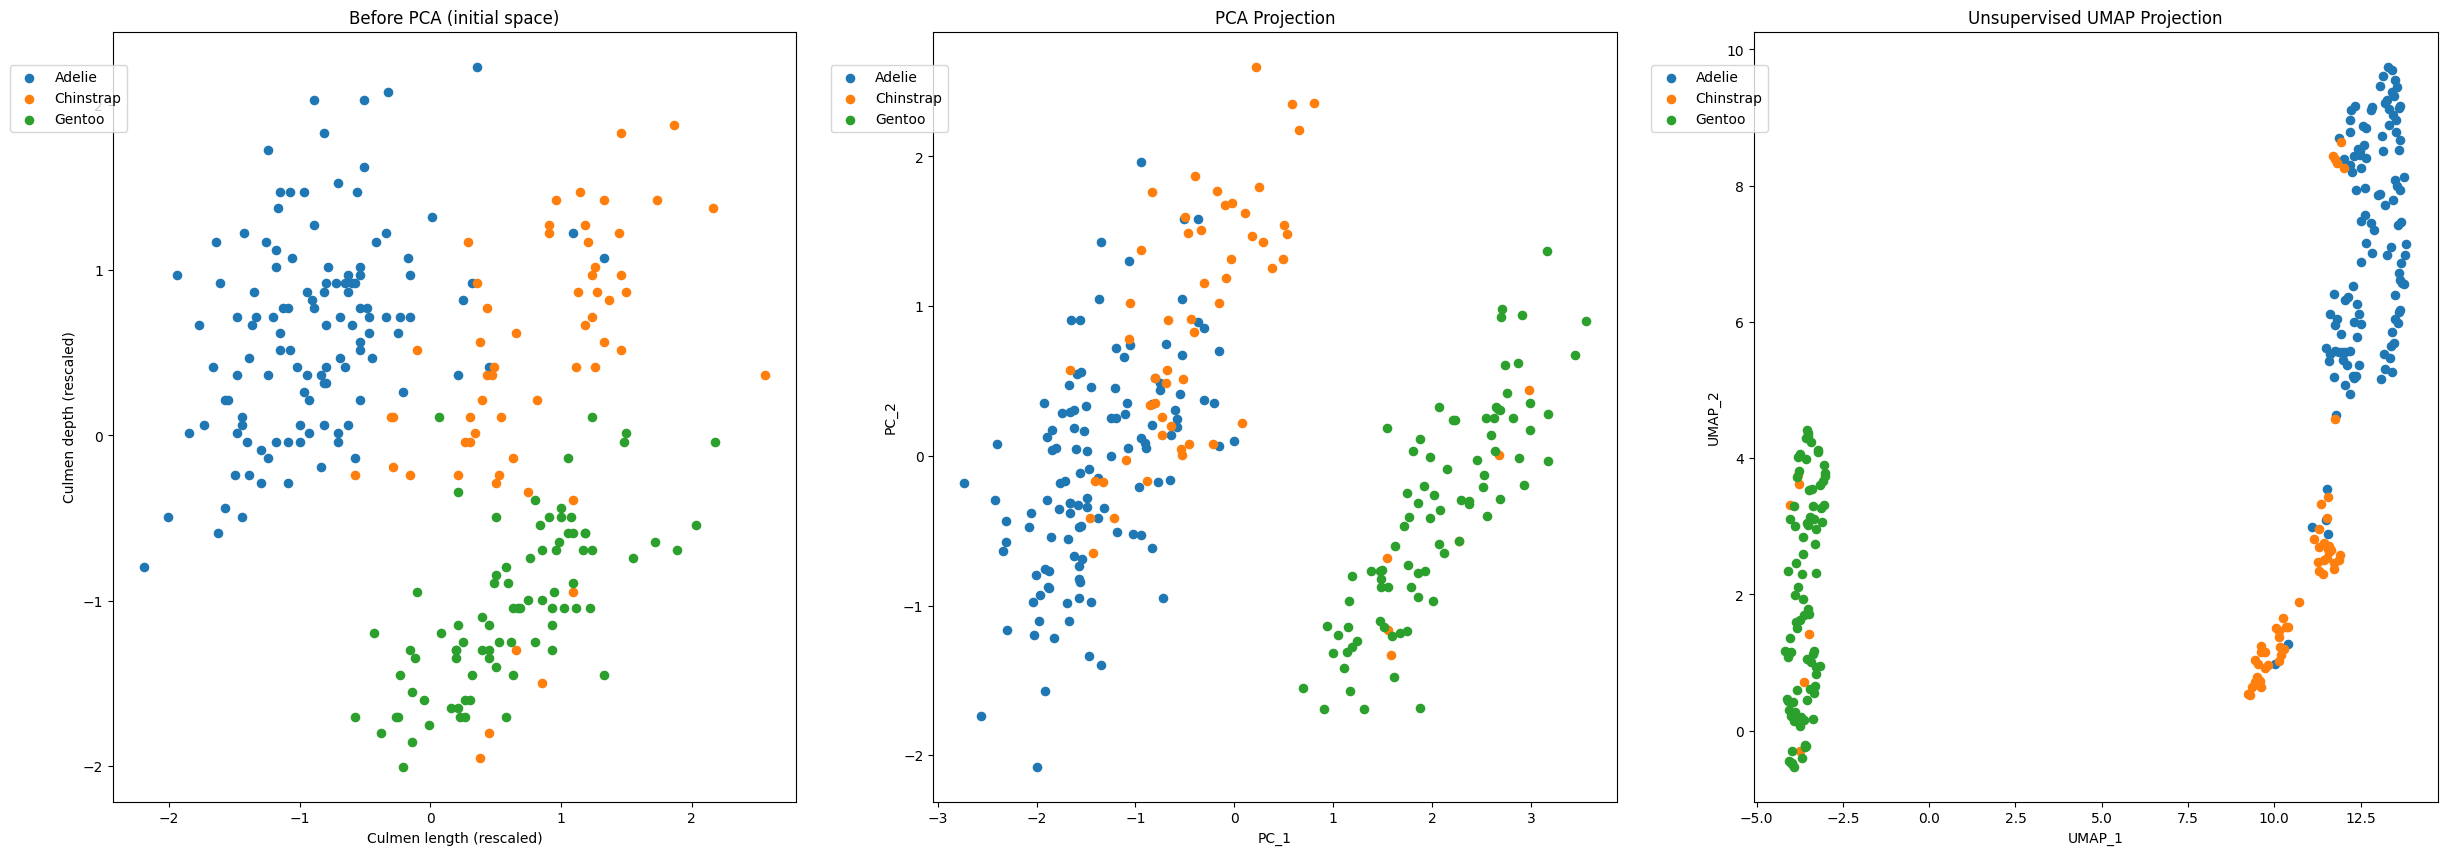

In [9]:
compare_embedding({'Before PCA (initial space)':{'x':X_train.iloc[:,0].to_numpy(), 'y':X_train.iloc[:,1].to_numpy(),'xlabel':'Culmen length (rescaled)', 'ylabel':'Culmen depth (rescaled)'},
 'PCA Projection':{'x':X_proj_PC[:,0], 'y':X_proj_PC[:,1],'xlabel':'PC_1', 'ylabel':'PC_2'},
 'Unsupervised UMAP Projection':{'x':X_umap[:,0], 'y':X_umap[:,1],'xlabel':'UMAP_1', 'ylabel':'UMAP_2'}
},labels_data=y_train_raw.to_numpy(),loc=(-.15,.87),marker_size=35)